# Student Performance Analysis and Prediction

## Project Overview

This project uses data analysis and machine learning to study student academic performance. The dataset contains information about students' study habits, absences, family background, and grades.

Two machine learning approaches are used:

- **Classification:** Predict whether a student passes or fails.
- **Regression:** Predict a student's final grade.

## Objectives

- Explore and understand the student performance dataset.
- Check for missing values, duplicate records, and potential outliers.
- Visualize patterns and relationships between student features and final grades.
- Build and evaluate classification and regression models.

## Tools and Technologies

Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, and the UCI Machine Learning Repository.

## 1. Import Libraries and Load Dataset

The required Python libraries are imported for data manipulation, visualization, and machine learning.

The Student Performance dataset is obtained from the UCI Machine Learning Repository using `ucimlrepo`. The feature data is stored in `X`, while the target columns containing the grades are stored in `Y`.

Both are combined into a single DataFrame named `data` for easier analysis.

In [8]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import mean_absolute_error , mean_squared_error
s_data = fetch_ucirepo(id = 320)
X = s_data.data.features
Y = s_data.data.targets

print(X.head())
print(X.columns)

data = pd.concat([X,Y], axis=1)
print(data.head())
print(data.columns)

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  higher internet  romantic  famrel  freetime goout Dalc Walc health absences  
0    yes       no        no       4         3     4    1    1      3        4  
1    yes      yes        no       5         3     3    1    1      3        2  
2    yes      yes        no       4         3     2    2    3      3        6  
3    yes      yes       yes       3         2     2    1    1      5        0  
4    yes       no        no       4         3     2    1    2      5        0  

[5 rows x 30 columns]
Index(['sc

## 2. Data Inspection and Cleaning

Data inspection helps us understand the structure and quality of the dataset before applying machine learning.

The following checks are performed:

- `info()` displays column names, data types, and non-null counts.
- `isnull().sum()` checks for missing values.
- `duplicated().sum()` checks for duplicate rows.
- `describe()` provides summary statistics for numerical columns.
- A box plot of absences helps identify potential outliers.

Outliers are not automatically removed because unusually high absences may represent genuine student records. The data should only be changed when there is a valid reason.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

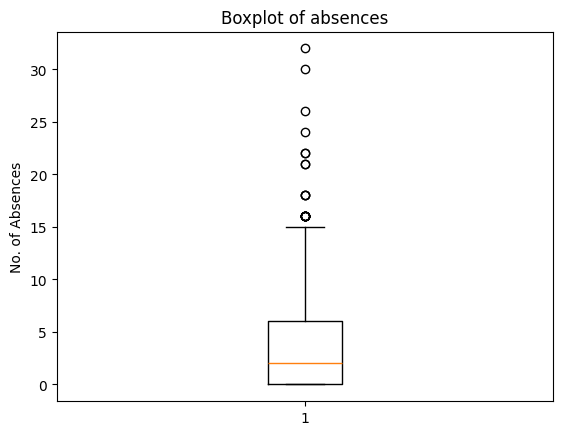

In [9]:
print(data.info())
print("Missing values : \n",data.isnull().sum())
print("Duplicate values :\n"  , data.duplicated().sum())
print(data.describe())

plt.boxplot(data["absences"])
plt.title("Boxplot of absences")
plt.ylabel("No. of Absences")
plt.show()

## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us identify patterns and understand the relationships within the dataset before training machine learning models.

The following visualizations are used:

1. **Histogram:** Shows the distribution of students' final grades (`G3`).
2. **Scatter plot:** Examines the relationship between study time and final grades.
3. **Scatter plot:** Examines the relationship between absences and final grades.
4. **Bar chart:** Compares average final grades across study-time categories.
5. **Correlation heatmap:** Shows the strength and direction of linear relationships between selected numerical variables.

These visualizations help us explore possible patterns, but they do not by themselves prove that one factor causes changes in grades.

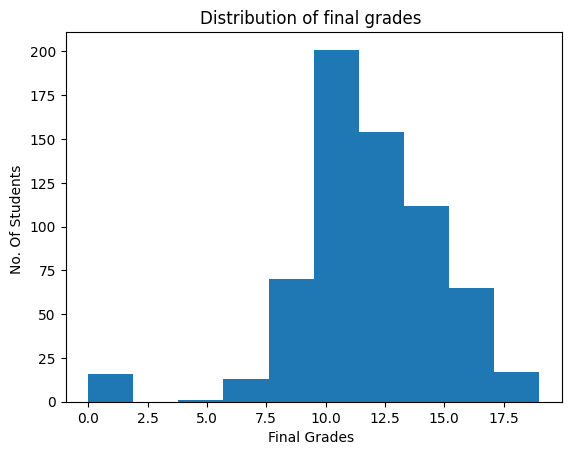

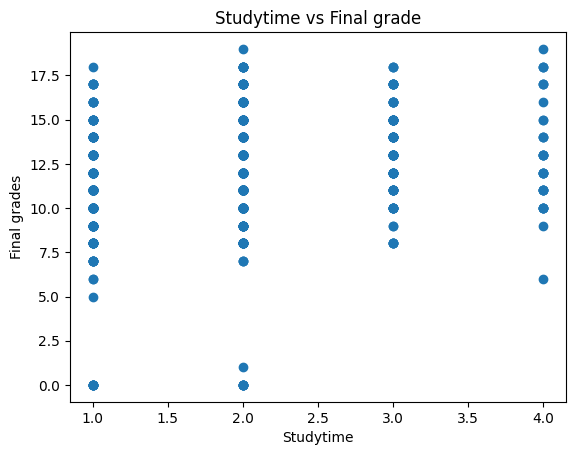

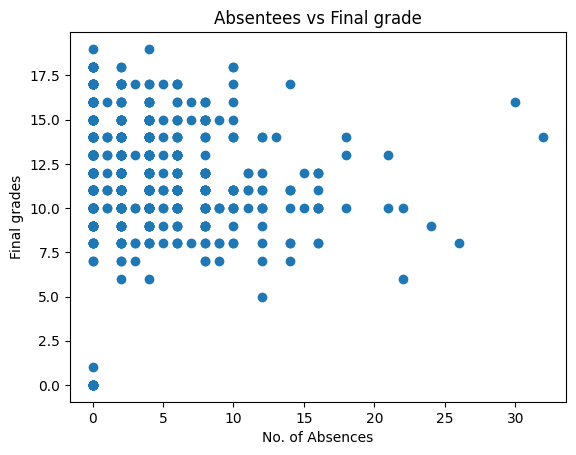

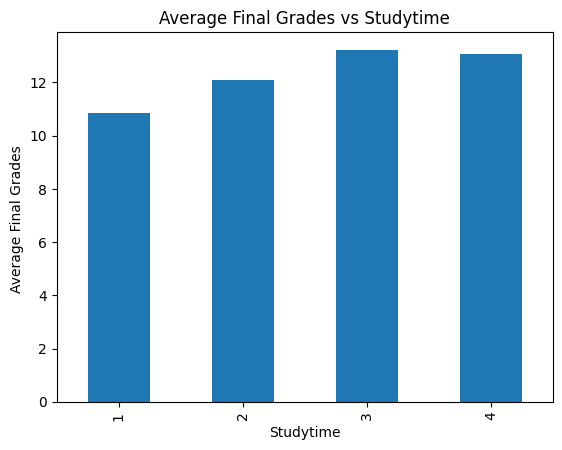

                age  studytime  absences        G1        G2        G3
age        1.000000  -0.008415  0.149998 -0.174322 -0.107119 -0.106505
studytime -0.008415   1.000000 -0.118389  0.260875  0.240498  0.249789
absences   0.149998  -0.118389  1.000000 -0.147149 -0.124745 -0.091379
G1        -0.174322   0.260875 -0.147149  1.000000  0.864982  0.826387
G2        -0.107119   0.240498 -0.124745  0.864982  1.000000  0.918548
G3        -0.106505   0.249789 -0.091379  0.826387  0.918548  1.000000


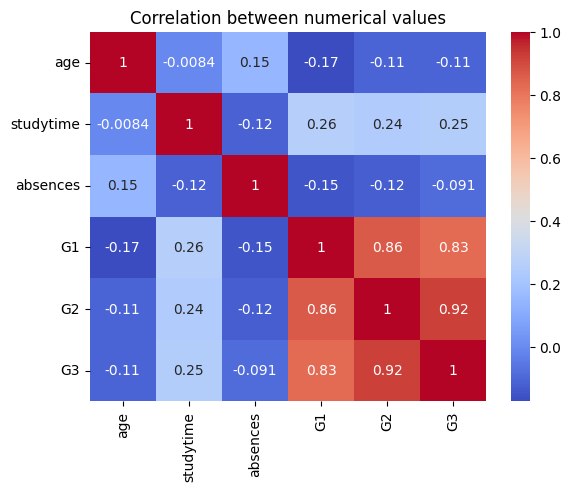

In [10]:
plt.hist(data["G3"],bins =10)
plt.xlabel("Final Grades ")
plt.ylabel("No. Of Students ")
plt.title("Distribution of final grades ")
plt.show()

plt.scatter(data["studytime"],data["G3"])
plt.xlabel("Studytime")
plt.ylabel("Final grades")
plt.title("Studytime vs Final grade")
plt.show()


plt.scatter(data["absences"],data["G3"])
plt.xlabel("No. of Absences")
plt.ylabel("Final grades")
plt.title("Absentees vs Final grade")
plt.show()

study = data.groupby("studytime")["G3"].mean()
study.plot(kind = "bar")
plt.xlabel("Studytime")
plt.ylabel("Average Final Grades ")
plt.title("Average Final Grades vs Studytime")
plt.show()

correlation = data[["age", "studytime", "absences", "G1", "G2", "G3"]].corr()
print(correlation)
sns.heatmap(correlation , annot= True , cmap="coolwarm")
plt.title("Correlation between numerical values")
plt.show()

## EDA Observations

1. **Distribution of Final Grades:** The histogram shows how students' final grades (`G3`) are distributed across different grade ranges.

2. **Study Time vs. Final Grades:** Study time has a weak positive correlation with final grades (approximately 0.25). This suggests that students with more study time may tend to achieve slightly higher grades, although the relationship is not strong.

3. **Absences vs. Final Grades:** Absences have a weak negative correlation with final grades (approximately -0.09). This indicates a very weak linear relationship between absences and final grades in this dataset.

4. **Average Grades by Study Time:** The bar chart compares the average final grades of students across different study-time categories and helps identify differences between the groups.

5. **Correlation Heatmap:** Previous grades (`G1` and `G2`) show stronger positive correlations with final grades (`G3`) than study time or absences. However, `G1` and `G2` are not used as input features in the models developed in this project.

### Overall Observation

The EDA helps us understand the distribution of student grades and explore relationships between selected student characteristics and academic performance. These relationships do not prove cause and effect, and other factors may also influence students' final grades.

## 4. Classification Model — Pass or Fail

Classification is a supervised machine learning task used to predict a category rather than a continuous number.

In this project, students are classified into two categories using their final grade (`G3`):

- **Pass (1):** Final grade is 10 or above.
- **Fail (0):** Final grade is below 10.

The input features are age, study time, previous failures, and absences. The data is split into training and testing sets. Logistic Regression is trained on the training data and evaluated on the unseen test data.

The final grade (`G3`) is used to create the Pass/Fail target, not as an input feature. Earlier grades (`G1` and `G2`) are also excluded from the input features in this initial model.

In [11]:
data["performance"] = (data["G3"]>=10).astype(int)
x=data[["age","studytime","failures","absences"]]
y=data["performance"]



x_train,x_test, y_train, y_test = train_test_split(x , y , test_size=0.2 , random_state=42,stratify=y)
model= LogisticRegression(max_iter=1000)
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
precision = precision_score(y_test, y_pred)
print("Precision:", precision)
recall = recall_score(y_test, y_pred)
print("Recall:", recall)

Accuracy: 0.8384615384615385
Precision: 0.8503937007874016
Recall: 0.9818181818181818


### Classification Results

The model achieved the following results on the test set:

- **Accuracy:** 83.85%
- **Precision:** 85.04%
- **Recall:** 98.18%

Accuracy measures the overall proportion of correct predictions. Precision indicates how often the model is correct when it predicts Pass. Recall indicates how many of the actual Pass cases it successfully identifies.

The high recall suggests that the model identifies most actual Pass cases. However, these metrics alone do not tell us how well the model identifies Fail cases. Further evaluation, such as a confusion matrix, could provide additional insight.

## 5. Regression Model — Final Grade Prediction

Regression is a supervised machine learning task used to predict a numerical value.

In this project, Linear Regression predicts students' final grades (`G3`) using four input features: age, study time, previous failures, and absences.

The dataset is divided into training and testing sets. The model learns patterns from the training data and predicts grades for the test data. Actual grades are then compared with predicted grades to evaluate the model.

In [12]:
A = data[["age", "studytime", "failures", "absences"]]
B = data["G3"]

A_train, A_test, B_train, B_test = train_test_split(A,B,test_size=0.2,random_state=42)
reg_model = LinearRegression()
reg_model.fit(A_train , B_train)
B_pred = reg_model.predict(A_test)

comparison = pd.DataFrame({
    "Actual Grade " :B_test.to_numpy() ,
    "Predicted Grade " :B_pred })
print(comparison.head(10))


mae = mean_absolute_error(B_test, B_pred)
rmse  = np.sqrt(mean_squared_error(B_test, B_pred))
print("MAE:",mae)
print("RMSE:",rmse)


   Actual Grade   Predicted Grade 
0             19         12.328957
1             12         12.353614
2             18         12.404901
3             11         12.296656
4             11         12.346957
5             17         13.042511
6             18         12.391586
7              8          6.124305
8             10         12.215040
9             11         12.322299
MAE: 2.205488597876903
RMSE: 2.879280085063023


### Regression Results

The model achieved the following evaluation results:

- **Mean Absolute Error (MAE):** Approximately 2.21 marks.
- **Root Mean Squared Error (RMSE):** Approximately 2.88 marks.

MAE measures the average absolute difference between actual and predicted grades. RMSE also measures prediction error but penalizes larger errors more heavily.

These results suggest that the predicted grades can differ noticeably from actual grades. The model provides estimates rather than exact predictions.

### Actual vs. Predicted Grades

This scatter plot compares the actual final grades with the grades predicted by the Linear Regression model.

The dashed diagonal line represents perfect predictions, where the predicted grade equals the actual grade.

- Points close to the line represent more accurate predictions.
- Points above the line indicate overprediction.
- Points below the line indicate underprediction.

The graph helps us visually understand how closely the model's predictions match the actual grades.

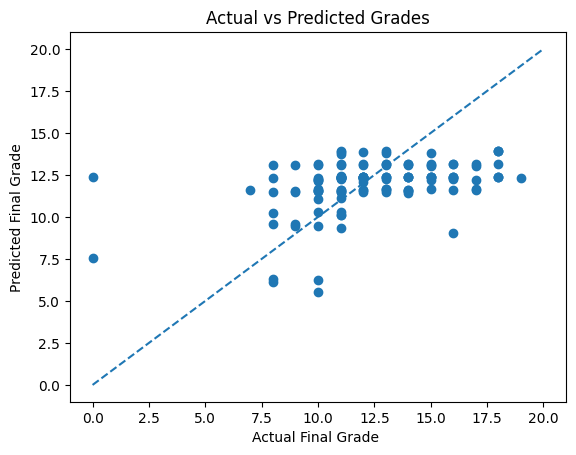

In [13]:
plt.scatter(B_test,B_pred)
plt.plot([0,20],[0,20], linestyle= "--")
plt.xlabel("Actual Final Grade ")
plt.ylabel("Predicted Final Grade")
plt.title("Actual vs Predicted Grades")
plt.show()


## 6. Key Insights

1. The dataset contains 649 student records and 33 columns.
2. The initial data checks found no missing values or duplicate rows.
3. The EDA visualizations help explore the distribution of final grades and the relationships between study time, absences, and academic performance.
4. The classification model achieved 83.85% accuracy and a recall of 98.18% for the Pass category.
5. The regression model achieved an MAE of approximately 2.21 marks and an RMSE of approximately 2.88 marks.
6. The actual-versus-predicted graph helps identify where the regression model makes larger prediction errors.

## 7. Limitations

- The models use only four input features, so other factors affecting academic performance are not included.
- Relationships observed in the dataset do not necessarily establish cause and effect.
- The results depend on the selected dataset, features, and train/test split.
- The predictions should not be treated as definitive judgments about individual students.

## 8. Conclusion

This project demonstrates the use of data analysis and machine learning to study student performance. Exploratory Data Analysis was used to examine the dataset, Logistic Regression was applied to Pass/Fail classification, and Linear Regression was used to predict final grades.

The models produced measurable results, but their predictions have limitations. This project provides a beginner-level demonstration of how machine learning can support data analysis and prediction.